In [36]:
import tensorflow as tf
import pathlib

dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

data_dir = tf.keras.utils.get_file(
    "flower_photos",
    origin=dataset_url,
    untar=True
)

data_dir = pathlib.Path(data_dir)

print(data_dir)

/root/.keras/datasets/flower_photos


In [37]:
IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE
)

Found 3670 files belonging to 1 classes.
Using 2936 files for training.
Found 3670 files belonging to 1 classes.
Using 734 files for validation.


In [38]:
class_names = train_ds.class_names
print(class_names)

['flower_photos']


In [39]:
import os

print(os.listdir(data_dir))

['flower_photos']


In [40]:
import pathlib
import os

data_dir = pathlib.Path(data_dir) / "flower_photos"

print(data_dir)
print(os.listdir(data_dir))

/root/.keras/datasets/flower_photos/flower_photos
['sunflowers', 'dandelion', 'roses', 'tulips', 'LICENSE.txt', 'daisy']


In [41]:
IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE
)

Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.


In [42]:
class_names = train_ds.class_names
print(class_names)

['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


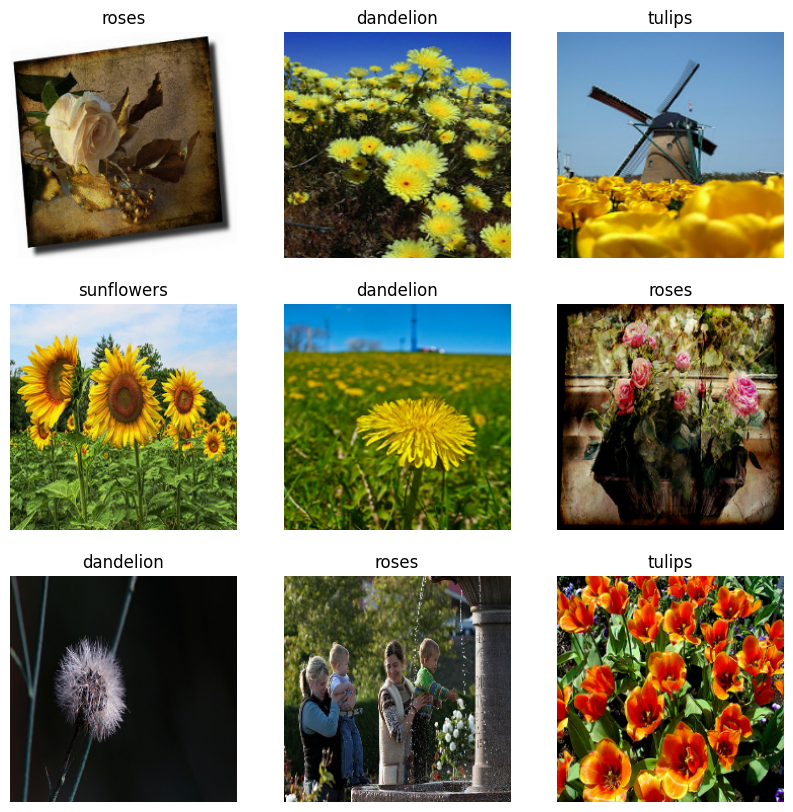

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,10))

for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3,3,i+1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.show()

In [44]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

In [45]:
from tensorflow import keras
from tensorflow.keras import layers

num_classes = len(class_names)

model = keras.Sequential([
    layers.Rescaling(1./255, input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)),

    layers.Conv2D(16, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     6,422,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,446,885 (24.59 MB)

 Trainable params: 6,446,885 (24.59 MB)

 Non-trainable params: 0 (0.00 B)

In [46]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [47]:
epochs = 10

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs
)

Epoch 1/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 185s 2s/step - accuracy: 0.4033 - loss: 1.3669 - val_accuracy: 0.5777 - val_loss: 1.0637
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 166s 2s/step - accuracy: 0.5899 - loss: 1.0092 - val_accuracy: 0.6008 - val_loss: 1.0496
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 165s 2s/step - accuracy: 0.6727 - loss: 0.8444 - val_accuracy: 0.6553 - val_loss: 0.8795
Epoch 4/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 165s 2s/step - accuracy: 0.7650 - loss: 0.6354 - val_accuracy: 0.6580 - val_loss: 0.9264
Epoch 5/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 201s 2s/step - accuracy: 0.8583 - loss: 0.4137 - val_accuracy: 0.6635 - val_loss: 0.9765
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 164s 2s/step - accuracy: 0.9240 - loss: 0.2236 - val_accuracy: 0.6662 - val_loss: 1.0584
Epoch 7/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 204s 2s/step - accuracy: 0.9666 - loss: 0.1099 - val_accuracy: 0.6540 - val_loss: 1.2567
Epoch 8/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 202s 2s/step - accuracy: 0.9819 - loss: 0.0649 - val_accuracy: 0.6676 - v

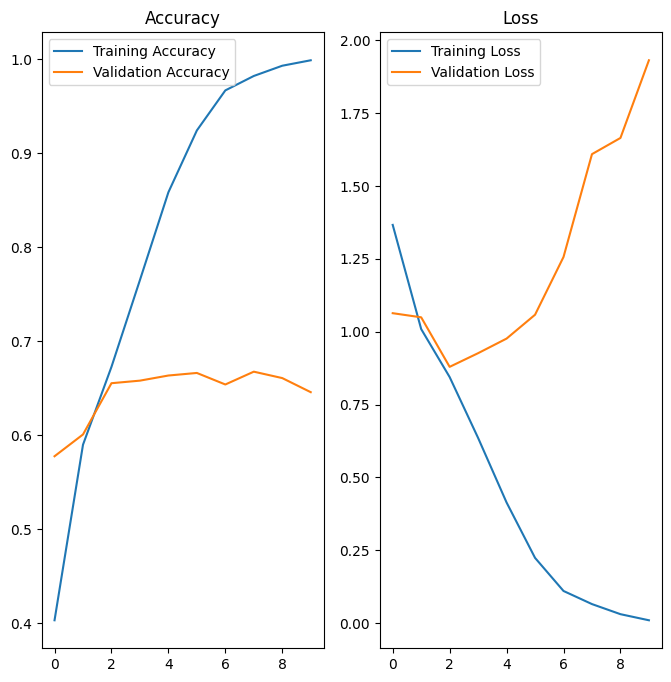

In [48]:
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(epochs)

plt.figure(figsize=(8,8))

plt.subplot(1,2,1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend()
plt.title('Accuracy')

plt.subplot(1,2,2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend()
plt.title('Loss')

plt.show()

In [53]:
from tensorflow.keras.utils import load_img, img_to_array
import numpy as np

In [52]:
img_path = "C:\Users\SOWMIYA A\Downloads\WhatsApp Image 2026-10-14 at 5.15.56 PM.jpeg"

img = load_img(
    img_path,
    target_size=(IMG_HEIGHT, IMG_WIDTH)
)

img_array = img_to_array(img)
img_array = tf.expand_dims(img_array, 0)

prediction = model.predict(img_array)

score = tf.nn.softmax(prediction[0])

print(
    "This flower is:",
    class_names[np.argmax(score)]
)

print(
    "Confidence:",
    round(100 * np.max(score), 2),
    "%"
)

SyntaxError: (unicode error) 'unicodeescape' codec can't decode bytes in position 2-3: truncated \UXXXXXXXX escape (1737028937.py, line 1)

In [54]:
from google.colab import files

uploaded = files.upload()

Saving WhatsApp Image 2026-10-14 at 5.20.11 PM.jpeg to WhatsApp Image 2026-10-14 at 5.20.11 PM (1).jpeg


In [ ]:
import os
print(os.listdir())

In [ ]:
img_path = "WhatsApp Image 2026-10-14 at 5.20.11 PM.jpeg"

In [ ]:
from tensorflow.keras.utils import load_img, img_to_array
import numpy as np
import tensorflow as tf

img = load_img(
    img_path,
    target_size=(IMG_HEIGHT, IMG_WIDTH)
)

img_array = img_to_array(img)

img_array = tf.expand_dims(img_array, 0)

prediction = model.predict(img_array)

score = tf.nn.softmax(prediction[0])

print("Flower Prediction:", class_names[np.argmax(score)])
print("Confidence:", round(100 * np.max(score), 2), "%")

In [ ]:
model.save("flower_classifier_model.h5")

In [ ]:
model.save("flower_classifier_model.keras")

In [56]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [57]:
model.save("/content/drive/MyDrive/flower_classifier_model.h5")

In [58]:
import os

print(os.path.exists("/content/drive/MyDrive/flower_classifier_model.h5"))

True
